In [1]:
import json
from pathlib import Path

ROOT = Path(r"C:\data\msd\Task04_Hippocampus")
meta = json.loads((ROOT / "dataset.json").read_text())

print(meta.keys())

dict_keys(['name', 'description', 'reference', 'licence', 'relase', 'tensorImageSize', 'modality', 'labels', 'numTraining', 'numTest', 'training', 'test'])


In [2]:
# 1. What the dataset says about itself
for key in ["name", "description", "reference", "licence", "release", "modality", "labels", "numTraining", "numTest"]:
    print(f"{key:12}: {meta.get(key)}")

print("\nEntries listed in 'training':", len(meta["training"]))
print("Entries listed in 'test':    ", len(meta["test"]))
print("Example entry:", meta["training"][0])

# 2. Does every listed file actually exist on disk?
missing = []
for entry in meta["training"]:
    for kind in ["image", "label"]:
        path = ROOT / entry[kind]
        if not path.exists():
            missing.append(str(path))

print("\nMissing files:", len(missing))
print(missing[:5])

# 3. How much junk is in the folder that the list ignores?
on_disk = list((ROOT / "imagesTr").glob("*.nii.gz"))
junk = [p.name for p in on_disk if p.name.startswith("._")]
print(f"\nFiles in imagesTr matching *.nii.gz: {len(on_disk)}  (of which ._ junk: {len(junk)})")

name        : Hippocampus
description : Left and right hippocampus segmentation
reference   :  Vanderbilt University Medical Center
licence     : CC-BY-SA 4.0
release     : None
modality    : {'0': 'MRI'}
labels      : {'0': 'background', '1': 'Anterior', '2': 'Posterior'}
numTraining : 260
numTest     : 130

Entries listed in 'training': 260
Entries listed in 'test':     130
Example entry: {'image': './imagesTr/hippocampus_367.nii.gz', 'label': './labelsTr/hippocampus_367.nii.gz'}

Missing files: 0
[]

Files in imagesTr matching *.nii.gz: 261  (of which ._ junk: 1)


Stack size (boxes): (36, 57, 37)
Box size (mm)     : [1. 1. 1.]
Same ruler for image and label? True
anterior : 2212 boxes x 1.00 mm^3 = 2212 mm^3
posterior: 1939 boxes x 1.00 mm^3 = 1939 mm^3


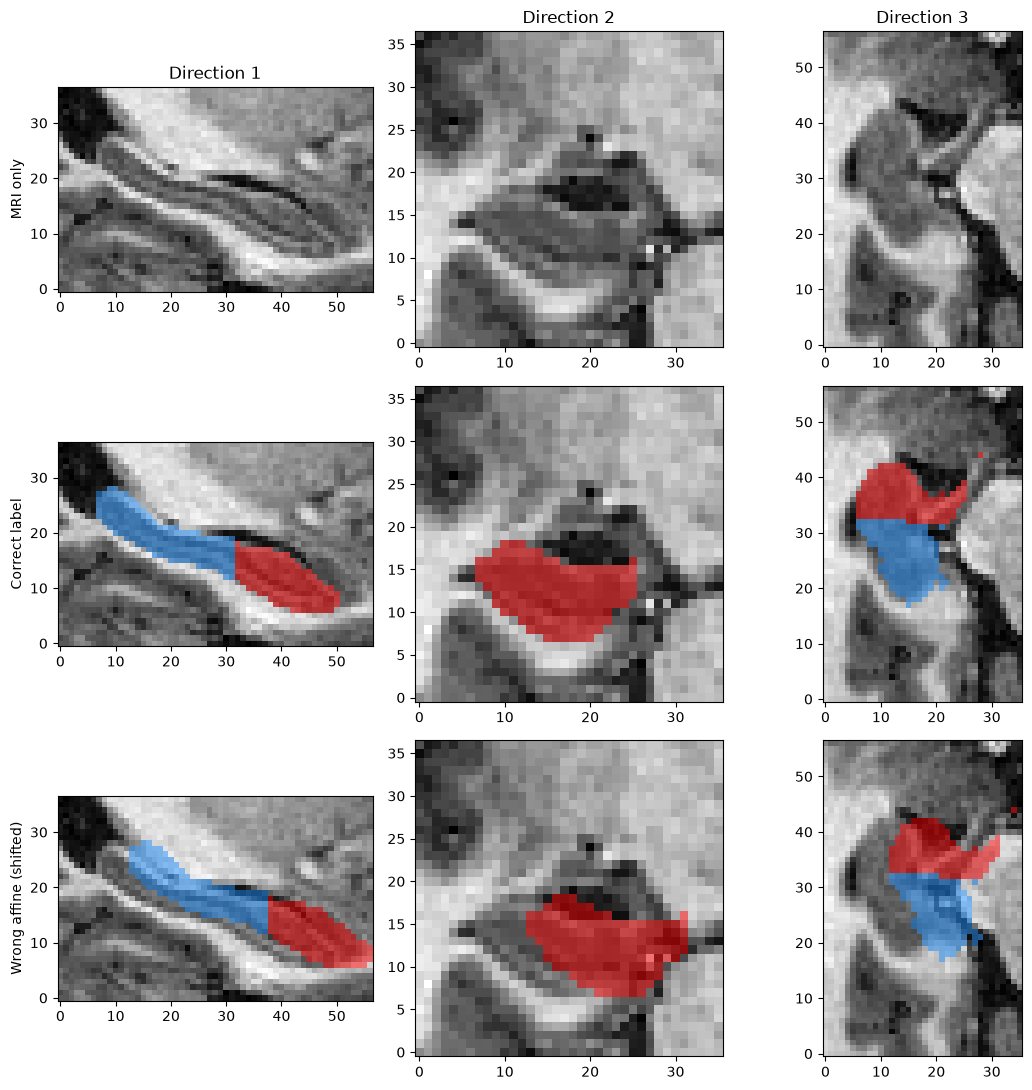

In [3]:
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

entry = meta["training"][0]
img = nib.load(ROOT / entry["image"])
lbl = nib.load(ROOT / entry["label"])
image = img.get_fdata()
label = np.asarray(lbl.dataobj)
spacing = np.linalg.norm(img.affine[:3, :3], axis=0)

print("Stack size (boxes):", image.shape)
print("Box size (mm)     :", np.round(spacing, 3))
print("Same ruler for image and label?", np.allclose(img.affine, lbl.affine))
for v, name in [(1, "anterior"), (2, "posterior")]:
    n = int((label == v).sum())
    print(f"{name:9}: {n} boxes x {np.prod(spacing):.2f} mm^3 = {n*np.prod(spacing):.0f} mm^3")

# Pick the slice with the most hippocampus in each of the 3 directions
fg = label > 0
cuts = [np.argmax(fg.sum(axis=(1, 2))), np.argmax(fg.sum(axis=(0, 2))), np.argmax(fg.sum(axis=(0, 1)))]
slices = [
    (image[cuts[0], :, :], label[cuts[0], :, :]),
    (image[:, cuts[1], :], label[:, cuts[1], :]),
    (image[:, :, cuts[2]], label[:, :, cuts[2]]),
]
colors = ListedColormap(["red", "dodgerblue"])   # 1 = anterior (red), 2 = posterior (blue)

fig, axes = plt.subplots(3, 3, figsize=(11, 11))
for col, (im, lb) in enumerate(slices):
    # Row 1: the photo only
    axes[0, col].imshow(im.T, cmap="gray", origin="lower")
    # Row 2: photo + correct colouring
    axes[1, col].imshow(im.T, cmap="gray", origin="lower")
    axes[1, col].imshow(np.ma.masked_equal(lb, 0).T, cmap=colors, vmin=1, vmax=2, alpha=0.5, origin="lower")
    # Row 3: what a WRONG ruler looks like (label shifted by 6 boxes)
    shifted = np.roll(lb, 6, axis=0)
    axes[2, col].imshow(im.T, cmap="gray", origin="lower")
    axes[2, col].imshow(np.ma.masked_equal(shifted, 0).T, cmap=colors, vmin=1, vmax=2, alpha=0.5, origin="lower")
    axes[0, col].set_title(f"Direction {col+1}")
axes[0, 0].set_ylabel("MRI only")
axes[1, 0].set_ylabel("Correct label")
axes[2, 0].set_ylabel("Wrong affine (shifted)")
plt.tight_layout()
plt.show()

In [4]:
import pandas as pd

rows = []
for entry in meta["training"]:
    img = nib.load(ROOT / entry["image"])
    lbl = nib.load(ROOT / entry["label"])
    sp = np.linalg.norm(img.affine[:3, :3], axis=0)
    lab = np.asarray(lbl.dataobj)
    rows.append({
        "case": Path(entry["image"]).name,
        "shape": img.shape,
        "sx": sp[0], "sy": sp[1], "sz": sp[2],
        "axcodes": "".join(nib.aff2axcodes(img.affine)),
        "same_affine": np.allclose(img.affine, lbl.affine),
        "ant_mm3": (lab == 1).sum() * np.prod(sp),
        "post_mm3": (lab == 2).sum() * np.prod(sp),
    })
df = pd.DataFrame(rows)

print("Different shapes:", df["shape"].nunique())
print(df["shape"].value_counts().head())
print("\nSpacing values:\n", df[["sx", "sy", "sz"]].round(3).drop_duplicates())
print("\nOrientations:", df["axcodes"].value_counts().to_dict())
print("All image/label affines match:", df["same_affine"].all())
print("\nVolumes (mm^3):\n", df[["ant_mm3", "post_mm3"]].describe().round(0))

Different shapes: 236
shape
(37, 51, 33)    3
(35, 51, 35)    3
(35, 51, 36)    3
(32, 54, 34)    2
(37, 48, 34)    2
Name: count, dtype: int64

Spacing values:
     sx   sy   sz
0  1.0  1.0  1.0

Orientations: {'RAS': 260}
All image/label affines match: True

Volumes (mm^3):
        ant_mm3  post_mm3
count    260.0     260.0
mean    1715.0    1580.0
std      307.0     229.0
min     1054.0     993.0
25%     1515.0    1434.0
50%     1725.0    1578.0
75%     1909.0    1721.0
max     2593.0    2169.0


In [5]:
dims = np.array(df["shape"].tolist())
print("Largest size along each axis:", dims.max(axis=0))

Largest size along each axis: [43 59 47]


Train IDs: [1, 3, 4, 6, 7, 8, 11, 14, 15, 17, 19, 20, 23, 24, 25, 26, 33, 34, 35, 36] ... max 394
Test IDs : [2, 5, 9, 10, 12, 13, 16, 18, 21, 22, 27, 28, 29, 30, 43, 47, 54, 55, 59, 61] ... max 392
Total unique IDs: 390

Distinct origins: 2
                     case   ox   oy   oz
0  hippocampus_367.nii.gz  1.0  1.0  1.0
1  hippocampus_304.nii.gz  1.0  1.0  1.0
2  hippocampus_204.nii.gz  1.0  1.0  1.0
3  hippocampus_279.nii.gz  1.0  1.0  1.0
4  hippocampus_308.nii.gz  1.0  1.0  1.0
5  hippocampus_375.nii.gz  0.0  0.0  0.0
6  hippocampus_216.nii.gz  1.0  1.0  1.0
7  hippocampus_316.nii.gz  1.0  1.0  1.0
8  hippocampus_089.nii.gz  1.0  1.0  1.0
9  hippocampus_189.nii.gz  1.0  1.0  1.0


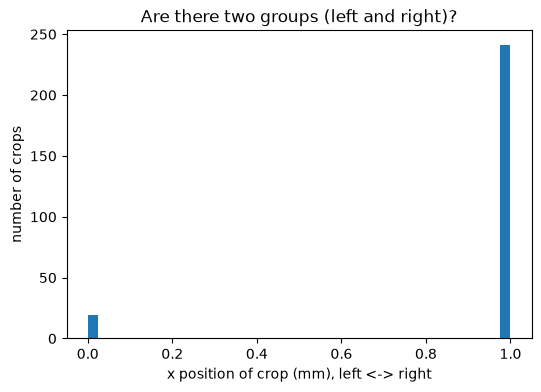

In [6]:
import re

df["id"] = df["case"].str.extract(r"(\d+)").astype(int)
test_ids = sorted(int(re.search(r"(\d+)", t).group(1)) for t in meta["test"])
train_ids = sorted(df["id"])
print("Train IDs:", train_ids[:20], "... max", max(train_ids))
print("Test IDs :", test_ids[:20], "... max", max(test_ids))
print("Total unique IDs:", len(set(train_ids) | set(test_ids)))

# Clue 2: where each crop sits in the scanner (mm)
origins = []
for entry in meta["training"]:
    aff = nib.load(ROOT / entry["image"]).affine
    origins.append(aff[:3, 3])
o = np.array(origins)
df["ox"], df["oy"], df["oz"] = o[:, 0], o[:, 1], o[:, 2]
print("\nDistinct origins:", len(np.unique(o.round(2), axis=0)))
print(df[["case", "ox", "oy", "oz"]].head(10).round(1))

plt.figure(figsize=(6, 4))
plt.hist(df["ox"], bins=40)
plt.xlabel("x position of crop (mm), left <-> right")
plt.ylabel("number of crops")
plt.title("Are there two groups (left and right)?")
plt.show()

dx > 0: 242 | dx < 0: 18


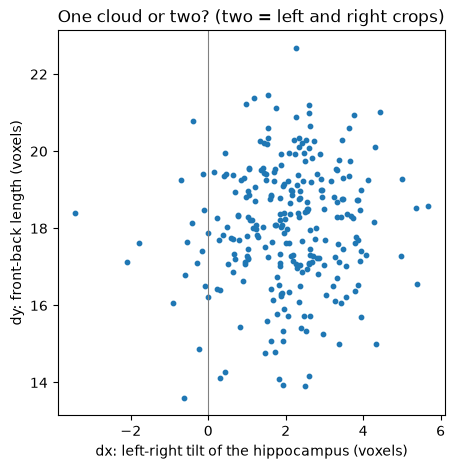

In [7]:
arrows = []
for entry in meta["training"]:
    lab = np.asarray(nib.load(ROOT / entry["label"]).dataobj)
    front = np.argwhere(lab == 1).mean(axis=0)   # centre of anterior part (voxel coords)
    back = np.argwhere(lab == 2).mean(axis=0)    # centre of posterior part
    arrows.append(front - back)                   # arrow from back to front
a = np.array(arrows)
df["dx"], df["dy"], df["dz"] = a[:, 0], a[:, 1], a[:, 2]

print("dx > 0:", (df.dx > 0).sum(), "| dx < 0:", (df.dx < 0).sum())

plt.figure(figsize=(5, 5))
plt.scatter(df.dx, df.dy, s=10)
plt.axvline(0, color="grey", lw=0.8)
plt.xlabel("dx: left-right tilt of the hippocampus (voxels)")
plt.ylabel("dy: front-back length (voxels)")
plt.title("One cloud or two? (two = left and right crops)")
plt.show()

First 5 fingerprints:
 [[1.223000e+02 3.914000e+02 5.871000e+02 8.398000e+02 9.947000e+02
  1.060000e+03]
 [1.170000e+02 3.436000e+02 5.557000e+02 7.238000e+02 8.335000e+02
  8.993000e+02]
 [3.938110e+04 1.302604e+05 2.181104e+05 3.150484e+05 3.847226e+05
  4.150157e+05]
 [6.520000e+01 2.663000e+02 4.076000e+02 5.435000e+02 6.467000e+02
  7.174000e+02]
 [1.400000e+01 4.100000e+01 6.500000e+01 8.800000e+01 1.000000e+02
  1.050000e+02]]
Crops whose closest partner is 3x closer than the next: 9 of 390


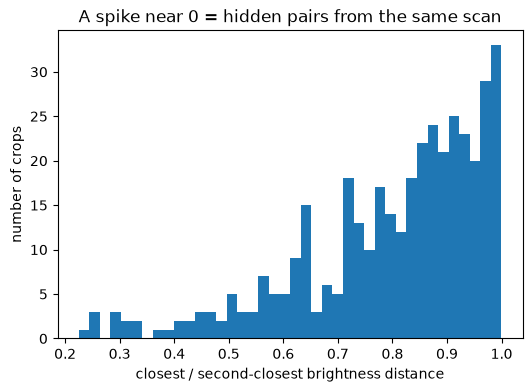

In [9]:
# Brightness fingerprint for ALL 390 crops (train + test, labels not needed)
all_imgs = [e["image"] for e in meta["training"]] + list(meta["test"])
feats, names = [], []
for p in all_imgs:
    x = np.asarray(nib.load(ROOT / p).dataobj).astype(np.float32).ravel()
    feats.append(np.percentile(x, [5, 25, 50, 75, 95, 99]))
    names.append(Path(p).name)
F = np.array(feats)
print("First 5 fingerprints:\n", F[:5].round(1))

Z = np.log1p(F)
Z = (Z - Z.mean(0)) / Z.std(0)                        # put all 6 numbers on one scale
D = np.linalg.norm(Z[:, None, :] - Z[None, :, :], axis=2)
np.fill_diagonal(D, np.inf)                              # ignore distance to itself
Ds = np.sort(D, axis=1)
ratio = Ds[:, 0] / Ds[:, 1]                              # closest partner vs second closest

print("Crops whose closest partner is 3x closer than the next:", (ratio < 0.33).sum(), "of", len(ratio))
plt.figure(figsize=(6, 4))
plt.hist(ratio, bins=40)
plt.xlabel("closest / second-closest brightness distance")
plt.ylabel("number of crops")
plt.title("A spike near 0 = hidden pairs from the same scan")
plt.show()